Code projet machine learning 

Adel Kheyar - Ilana Varinot - Florian Andre 

Partie 1 : Préparation et prétraitement

les dimensions et les 5 premières lignes 

In [4]:
import pandas as pd
import numpy as np
import string
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("~/Documents/School-codes/ECE/ING4/semestre_1/machine_learning/projet_final/amazBaby.xlsx")

print("Dimensions :", df.shape)
display(df.head())

Dimensions : (17016, 3)


,name,review,rating
0,Stop Pacifier Sucking without tears with Thumb...,All of my kids have cried non-stop when I trie...,5
1,Nature's Lullabies Second Year Sticker Calendar,We wanted to get something to keep track of ou...,5
2,"Lamaze Peekaboo, I Love You","One of baby's first and favorite books, and it...",4
3,SoftPlay Peek-A-Boo Where's Elmo A Children's ...,Very cute interactive book! My son loves this ...,5
4,Our Baby Girl Memory Book,"Beautiful book, I love it to record cherished ...",5


Le tableau des valeurs manquantes, capture 3 : la distribution des notes avec le graphique.

Types de variables :
name        str
review      str
rating    int64
dtype: object

Valeurs manquantes :


,nb_manquantes,pourcentage
name,1,0.01
review,85,0.50
rating,0,0.00



Distribution des notes :
rating
1    3516
2    2625
4    2719
5    8156
Name: count, dtype: int64


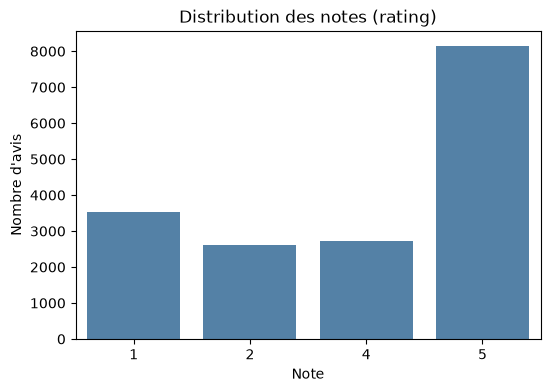

In [5]:
print("Types de variables :")
print(df.dtypes)

print("\nValeurs manquantes :")
manquantes = pd.DataFrame({
    "nb_manquantes": df.isna().sum(),
    "pourcentage": (df.isna().mean() * 100).round(2)
})
display(manquantes)

print("\nDistribution des notes :")
print(df["rating"].value_counts().sort_index())

plt.figure(figsize=(6, 4))
sns.countplot(x="rating", data=df, color="steelblue")
plt.title("Distribution des notes (rating)")
plt.xlabel("Note")
plt.ylabel("Nombre d'avis")
plt.show()

traitement des valeurs manquantes

In [6]:
df["name"] = df["name"].fillna("no name")
df["review"] = df["review"].fillna("")

print("Valeurs manquantes après traitement :")
print(df.isna().sum())

Valeurs manquantes après traitement :
name      0
review    0
rating    0
dtype: int64


suppression de la ponctuation et minuscules

In [7]:
def nettoyer(texte):
    texte = str(texte).lower()
    return texte.translate(str.maketrans("", "", string.punctuation))

df["review_clean"] = df["review"].apply(nettoyer)

display(df[["review", "review_clean"]].head(5))

,review,review_clean
0,All of my kids have cried non-stop when I trie...,all of my kids have cried nonstop when i tried...
1,We wanted to get something to keep track of ou...,we wanted to get something to keep track of ou...
2,"One of baby's first and favorite books, and it...",one of babys first and favorite books and it i...
3,Very cute interactive book! My son loves this ...,very cute interactive book my son loves this b...
4,"Beautiful book, I love it to record cherished ...",beautiful book i love it to record cherished t...


In [8]:
print("Nombre d'avis avant :", len(df))
print("Nombre d'avis avec note = 3 :", (df["rating"] == 3).sum())

df = df[df["rating"] != 3].copy()

print("Nombre d'avis après :", len(df))

Nombre d'avis avant : 17016
Nombre d'avis avec note = 3 : 0
Nombre d'avis après : 17016


suppression des avis neutres (note = 3)

In [9]:
print("Nombre d'avis avant :", len(df))
print("Nombre d'avis avec note = 3 :", (df["rating"] == 3).sum())

df = df[df["rating"] != 3].copy()

print("Nombre d'avis après :", len(df))

Nombre d'avis avant : 17016
Nombre d'avis avec note = 3 : 0
Nombre d'avis après : 17016


création de la variable sentiment

sentiment
 1    10875
-1     6141
Name: count, dtype: int64

Proportions :
sentiment
 1    0.6391
-1    0.3609
Name: proportion, dtype: float64


/tmp/ipykernel_107214/3741506274.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sentiment", data=df, palette=["tomato", "seagreen"], order=[-1, 1])


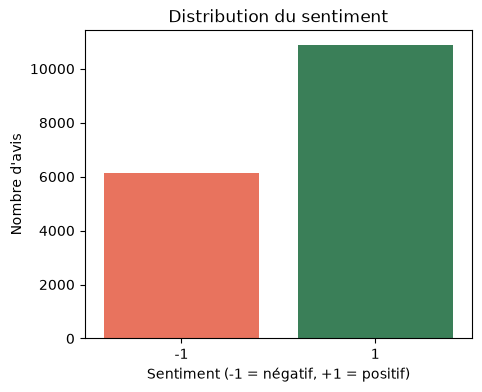

,rating,sentiment,review_clean
0,5,1,all of my kids have cried nonstop when i tried...
1,5,1,we wanted to get something to keep track of ou...
2,4,1,one of babys first and favorite books and it i...
3,5,1,very cute interactive book my son loves this b...
4,5,1,beautiful book i love it to record cherished t...


In [10]:
df["sentiment"] = np.where(df["rating"] >= 4, 1, -1)

print(df["sentiment"].value_counts())
print("\nProportions :")
print(df["sentiment"].value_counts(normalize=True).round(4))

plt.figure(figsize=(5, 4))
sns.countplot(x="sentiment", data=df, palette=["tomato", "seagreen"], order=[-1, 1])
plt.title("Distribution du sentiment")
plt.xlabel("Sentiment (-1 = négatif, +1 = positif)")
plt.ylabel("Nombre d'avis")
plt.show()

display(df[["rating", "sentiment", "review_clean"]].head())

Partie 2 : Division des données (80 % / 20 %)

division en jeu d’entraînement et jeu de test

In [11]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

train_data, test_data = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE
)

print("Taille du jeu complet        :", len(df))
print("Taille du jeu d'entraînement :", len(train_data))
print("Taille du jeu de test        :", len(test_data))
print("\nProportion train :", round(len(train_data) / len(df), 4))
print("Proportion test  :", round(len(test_data) / len(df), 4))

Taille du jeu complet        : 17016
Taille du jeu d'entraînement : 13612
Taille du jeu de test        : 3404

Proportion train : 0.8
Proportion test  : 0.2


vérification de la répartition des sentiments

,Train (nb),Test (nb),Train (%),Test (%)
sentiment,,,,
1,8703,2172,63.94,63.81
-1,4909,1232,36.06,36.19


/tmp/ipykernel_107214/3092657744.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sentiment", data=train_data, order=[-1, 1],
/tmp/ipykernel_107214/3092657744.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sentiment", data=test_data, order=[-1, 1],


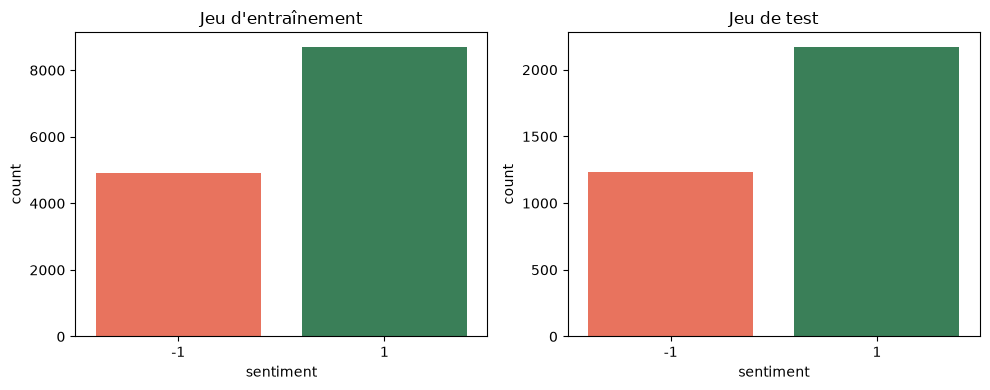

In [12]:
repartition = pd.DataFrame({
    "Train (nb)": train_data["sentiment"].value_counts(),
    "Test (nb)": test_data["sentiment"].value_counts(),
    "Train (%)": (train_data["sentiment"].value_counts(normalize=True) * 100).round(2),
    "Test (%)": (test_data["sentiment"].value_counts(normalize=True) * 100).round(2),
})
display(repartition)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="sentiment", data=train_data, order=[-1, 1],
              palette=["tomato", "seagreen"], ax=axes[0])
axes[0].set_title("Jeu d'entraînement")
sns.countplot(x="sentiment", data=test_data, order=[-1, 1],
              palette=["tomato", "seagreen"], ax=axes[1])
axes[1].set_title("Jeu de test")
plt.tight_layout()
plt.show()

Partie 3 : Représentation textuelle avec Bag of Words

définition du vocabulaire de 20 mots

In [13]:
significant_words = [
    "love", "great", "easy", "old", "little", "perfect", "loves", "well",
    "able", "car", "broke", "less", "even", "waste", "disappointed",
    "work", "product", "money", "would", "return"
]

print("Nombre de mots du vocabulaire :", len(significant_words))
print(significant_words)

Nombre de mots du vocabulaire : 20
['love', 'great', 'easy', 'old', 'little', 'perfect', 'loves', 'well', 'able', 'car', 'broke', 'less', 'even', 'waste', 'disappointed', 'work', 'product', 'money', 'would', 'return']


construction des vecteurs Bag of Words

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(vocabulary=significant_words)

X_train = vectorizer.fit_transform(train_data["review_clean"])
X_test = vectorizer.transform(test_data["review_clean"])

y_train = train_data["sentiment"].values
y_test = test_data["sentiment"].values

print("Forme de X_train :", X_train.shape)
print("Forme de X_test  :", X_test.shape)
print("Forme de y_train :", y_train.shape)
print("Forme de y_test  :", y_test.shape)

Forme de X_train : (13612, 20)
Forme de X_test  : (3404, 20)
Forme de y_train : (13612,)
Forme de y_test  : (3404,)


aperçu de la matrice et exemple concret

In [15]:
#aperçu de la matrice sous forme de tableau
bow_train = pd.DataFrame(X_train.toarray(), columns=significant_words)
display(bow_train.head(10))

#exemple : un avis et son vecteur
i = 0
print("Avis nettoyé :")
print(train_data["review_clean"].iloc[i])
print("\nVecteur Bag of Words correspondant :")
print(bow_train.iloc[i][bow_train.iloc[i] > 0])
print("\nSentiment :", y_train[i])

,love,great,easy,old,little,perfect,loves,well,able,car,broke,less,even,waste,disappointed,work,product,money,would,return
0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,2,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
6,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
7,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
9,0,0,0,2,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0


Avis nettoyé :
this is a trendy yet elegant bedding set it is well made with excellent fabrics and great detailing if you want something vintage chic for your daughters nursery and want to stay away from pink i would choose this

Vecteur Bag of Words correspondant :
great    1
well     1
would    1
Name: 0, dtype: int64

Sentiment : 1


fréquence de chaque mot dans le jeu d’entraînement

,occurrences
would,4272
great,3626
love,2897
little,2743
product,2587
well,2523
old,2293
easy,2170
even,1909
car,1462


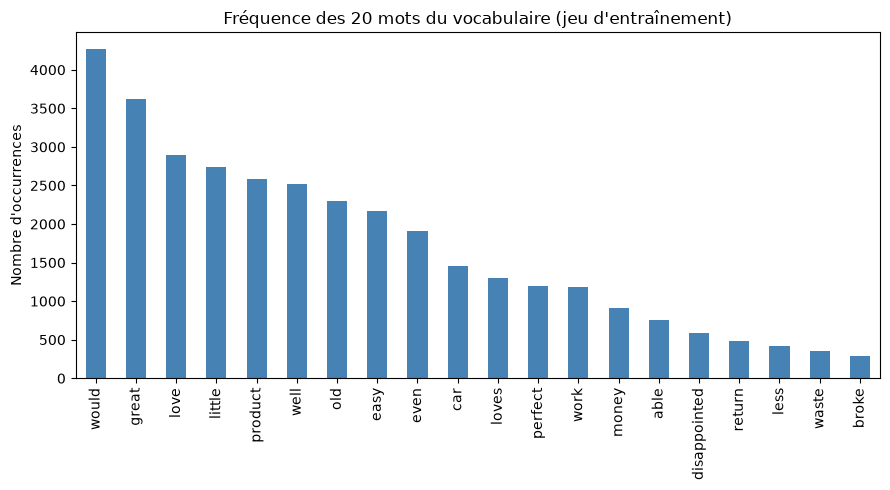

Avis sans aucun mot du vocabulaire : 2230 sur 13612


In [16]:
freq = pd.Series(np.asarray(X_train.sum(axis=0)).ravel(),
                 index=significant_words).sort_values(ascending=False)
display(freq.to_frame("occurrences"))

plt.figure(figsize=(9, 5))
freq.plot(kind="bar", color="steelblue")
plt.title("Fréquence des 20 mots du vocabulaire (jeu d'entraînement)")
plt.ylabel("Nombre d'occurrences")
plt.tight_layout()
plt.show()

print("Avis sans aucun mot du vocabulaire :",
      int((X_train.sum(axis=1) == 0).sum()), "sur", X_train.shape[0])

Partie 4 : Régression logistique

entraînement du modèle

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Modèle entraîné")
print("Classes apprises          :", model.classes_)
print("Nombre de coefficients    :", model.coef_.shape[1])
print("Intercept                 :", round(float(model.intercept_[0]), 4))

Modèle entraîné
Classes apprises          : [-1  1]
Nombre de coefficients    : 20
Intercept                 : 0.2527


tableau des coefficients

In [18]:
coefs = pd.DataFrame({
    "mot": significant_words,
    "coefficient": model.coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coefficient"])
coefs = coefs.sort_values("coefficient", ascending=False).reset_index(drop=True)

display(coefs.round(4))

print("Mots à coefficient positif :", int((coefs["coefficient"] > 0).sum()))
print("Mots à coefficient négatif :", int((coefs["coefficient"] < 0).sum()))
print("\nTop 5 mots positifs :", coefs.head(5)["mot"].tolist())
print("Top 5 mots négatifs :", coefs.tail(5)["mot"].tolist())

,mot,coefficient,odds_ratio
0,loves,1.7281,5.6300
1,perfect,1.5879,4.8935
2,love,1.3378,3.8108
3,easy,1.2604,3.5268
4,great,1.0827,2.9527
5,little,0.4809,1.6175
6,well,0.4458,1.5617
7,able,0.2482,1.2818
8,old,0.1579,1.1710
9,car,-0.0156,0.9846


Mots à coefficient positif : 9
Mots à coefficient négatif : 11

Top 5 mots positifs : ['loves', 'perfect', 'love', 'easy', 'great']
Top 5 mots négatifs : ['money', 'broke', 'waste', 'return', 'disappointed']


graphique des coefficients et sauvegarde du modèle

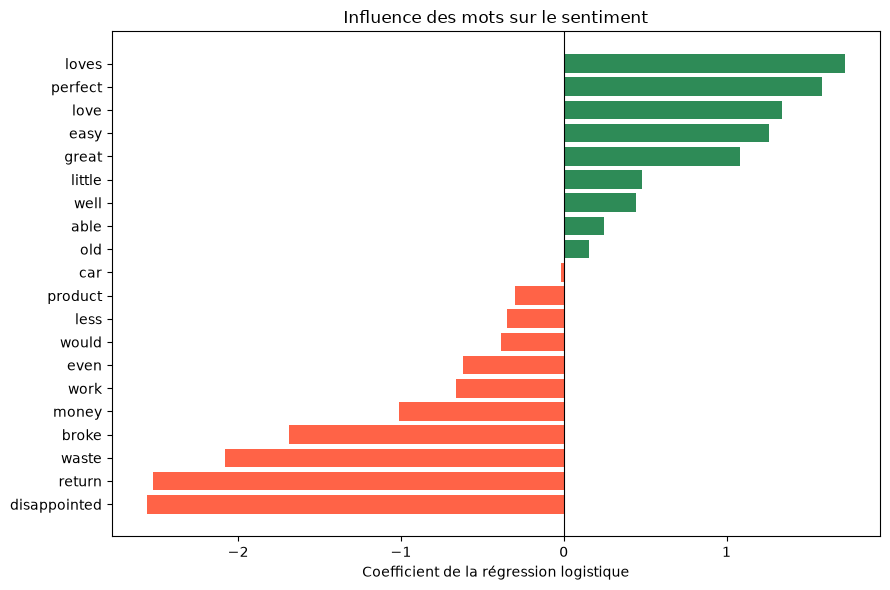

Modèle sauvegardé : modele_regression_logistique.joblib


In [19]:
import joblib

couleurs = ["seagreen" if c > 0 else "tomato" for c in coefs["coefficient"]]

plt.figure(figsize=(9, 6))
plt.barh(coefs["mot"][::-1], coefs["coefficient"][::-1], color=couleurs[::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient de la régression logistique")
plt.title("Influence des mots sur le sentiment")
plt.tight_layout()
plt.show()

joblib.dump({"model": model, "vectorizer": vectorizer},
            "modele_regression_logistique.joblib")
print("Modèle sauvegardé : modele_regression_logistique.joblib")

Partie 5 : Évaluation du modèle sur le jeu de test

accuracy et baseline

In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

#baseline : toujours prédire la classe majoritaire du jeu d'entraînement
classe_majoritaire = 1 if (y_train == 1).sum() >= (y_train == -1).sum() else -1
baseline_pred = np.full_like(y_test, classe_majoritaire)
baseline_accuracy = accuracy_score(y_test, baseline_pred)

print(f"Accuracy du modèle         : {accuracy:.4f}")
print(f"Baseline accuracy          : {baseline_accuracy:.4f}  (classe majoritaire = {classe_majoritaire:+d})")
print(f"Gain par rapport à baseline: {accuracy - baseline_accuracy:+.4f}")

Accuracy du modèle         : 0.7638
Baseline accuracy          : 0.6381  (classe majoritaire = +1)
Gain par rapport à baseline: +0.1257


matrice de confusion

,Prédit +1,Prédit -1
Réel +1,1957,215
Réel -1,589,643


Vrais positifs (TP) : 1957
Faux négatifs (FN)  : 215
Faux positifs (FP)  : 589
Vrais négatifs (TN) : 643


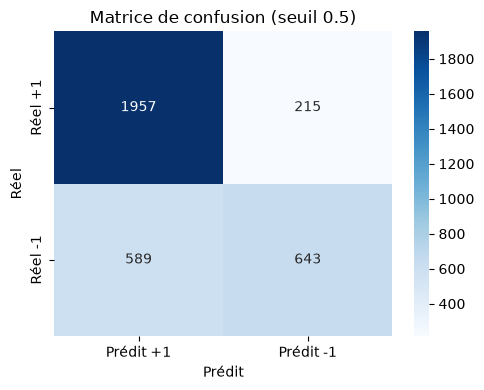

In [21]:
cm = confusion_matrix(y_test, y_pred, labels=[1, -1])
cm_df = pd.DataFrame(cm, index=["Réel +1", "Réel -1"],
                     columns=["Prédit +1", "Prédit -1"])
display(cm_df)

tp, fn, fp, tn = cm.ravel()
print(f"Vrais positifs (TP) : {tp}")
print(f"Faux négatifs (FN)  : {fn}")
print(f"Faux positifs (FP)  : {fp}")
print(f"Vrais négatifs (TN) : {tn}")

plt.figure(figsize=(5, 4))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de confusion (seuil 0.5)")
plt.ylabel("Réel")
plt.xlabel("Prédit")
plt.tight_layout()
plt.show()

precision et recall

In [22]:
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)

print(f"Precision (sklearn) : {precision:.4f}")
print(f"Recall    (sklearn) : {recall:.4f}")

#vérification avec les formules
print(f"\nPrecision = TP / (TP + FP) = {tp} / {tp + fp} = {tp / (tp + fp):.4f}")
print(f"Recall    = TP / (TP + FN) = {tp} / {tp + fn} = {tp / (tp + fn):.4f}")

resume = pd.DataFrame({
    "Métrique": ["Accuracy", "Baseline accuracy", "Precision", "Recall"],
    "Valeur": [accuracy, baseline_accuracy, precision, recall]
}).round(4)
display(resume)

Precision (sklearn) : 0.7687
Recall    (sklearn) : 0.9010

Precision = TP / (TP + FP) = 1957 / 2546 = 0.7687
Recall    = TP / (TP + FN) = 1957 / 2172 = 0.9010


,Métrique,Valeur
0,Accuracy,0.7638
1,Baseline accuracy,0.6381
2,Precision,0.7687
3,Recall,0.9010


Partie 6 : Analyse du seuil de classification (0,5 contre 0,9)

probabilités prédites

In [23]:
idx_pos = list(model.classes_).index(1)
proba_pos = model.predict_proba(X_test)[:, idx_pos]

print("Nombre de probabilités :", len(proba_pos))
print("10 premières probabilités d'être positif :", proba_pos[:10].round(3))
print("Min :", proba_pos.min().round(3), "| Max :", proba_pos.max().round(3))

Nombre de probabilités : 3404
10 premières probabilités d'être positif : [0.563 0.879 0.994 0.883 0.96  0.965 0.862 0.09  0.563 0.563]
Min : 0.0 | Max : 1.0


comparaison des seuils 0,5 et 0,9

In [24]:
def predire_avec_seuil(proba, seuil):
    return np.where(proba >= seuil, 1, -1)

lignes = []
for seuil in (0.5, 0.9):
    y_s = predire_avec_seuil(proba_pos, seuil)
    cm_s = confusion_matrix(y_test, y_s, labels=[1, -1])
    tp_s, fn_s, fp_s, tn_s = cm_s.ravel()
    lignes.append({
        "Seuil": seuil,
        "Avis classés positifs": int((y_s == 1).sum()),
        "TP": tp_s, "FP": fp_s, "FN": fn_s, "TN": tn_s,
        "Precision": precision_score(y_test, y_s, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_s, pos_label=1, zero_division=0),
    })

comparaison = pd.DataFrame(lignes).set_index("Seuil")
display(comparaison.round(4))

,Avis classés positifs,TP,FP,FN,TN,Precision,Recall
Seuil,,,,,,,
0.5,2546,1957,589,215,643,0.7687,0.9010
0.9,693,657,36,1515,1196,0.9481,0.3025


graphique de comparaison

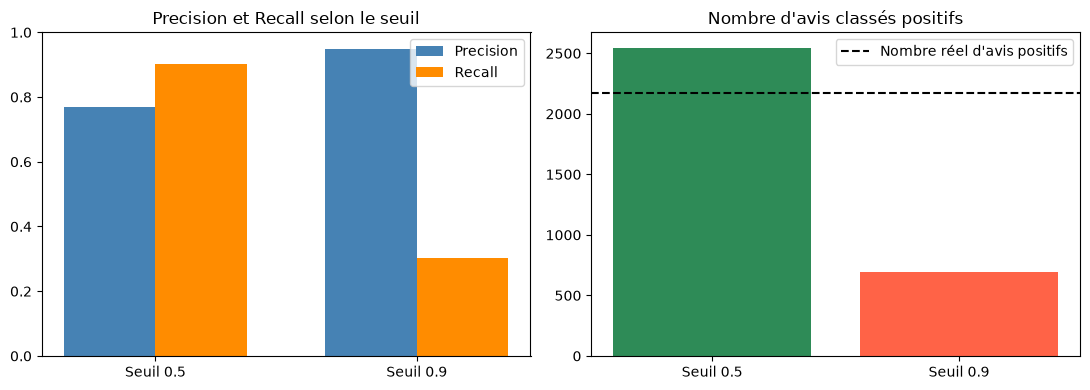

In [25]:
x = np.arange(2)
largeur = 0.35

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(x - largeur/2, comparaison["Precision"], largeur, label="Precision", color="steelblue")
axes[0].bar(x + largeur/2, comparaison["Recall"], largeur, label="Recall", color="darkorange")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Seuil 0.5", "Seuil 0.9"])
axes[0].set_ylim(0, 1)
axes[0].set_title("Precision et Recall selon le seuil")
axes[0].legend()

axes[1].bar(["Seuil 0.5", "Seuil 0.9"], comparaison["Avis classés positifs"],
            color=["seagreen", "tomato"])
axes[1].axhline((y_test == 1).sum(), color="black", linestyle="--",
                label="Nombre réel d'avis positifs")
axes[1].set_title("Nombre d'avis classés positifs")
axes[1].legend()

plt.tight_layout()
plt.show()

Partie 7 : Courbe Precision-Recall (200 seuils)

calcul de la précision et du rappel pour 200 seuils

In [26]:
seuils = np.linspace(0.01, 0.99, 200)

precisions = []
recalls = []
for s in seuils:
    y_s = predire_avec_seuil(proba_pos, s)
    precisions.append(precision_score(y_test, y_s, pos_label=1, zero_division=0))
    recalls.append(recall_score(y_test, y_s, pos_label=1, zero_division=0))

table_pr = pd.DataFrame({"seuil": seuils, "precision": precisions, "recall": recalls})
table_pr.to_csv("resultats_precision_recall.csv", index=False)

print("Nombre de seuils testés :", len(seuils))
print("Seuil min / max :", seuils.min().round(2), "/", seuils.max().round(2))
display(table_pr.iloc[::40].round(4))

Nombre de seuils testés : 200
Seuil min / max : 0.01 / 0.99


,seuil,precision,recall
0,0.0100,0.6439,0.9991
40,0.2070,0.6989,0.9876
80,0.4040,0.7340,0.9553
120,0.6010,0.8512,0.7136
160,0.7979,0.9206,0.5074


tracé de la courbe Precision-Recall

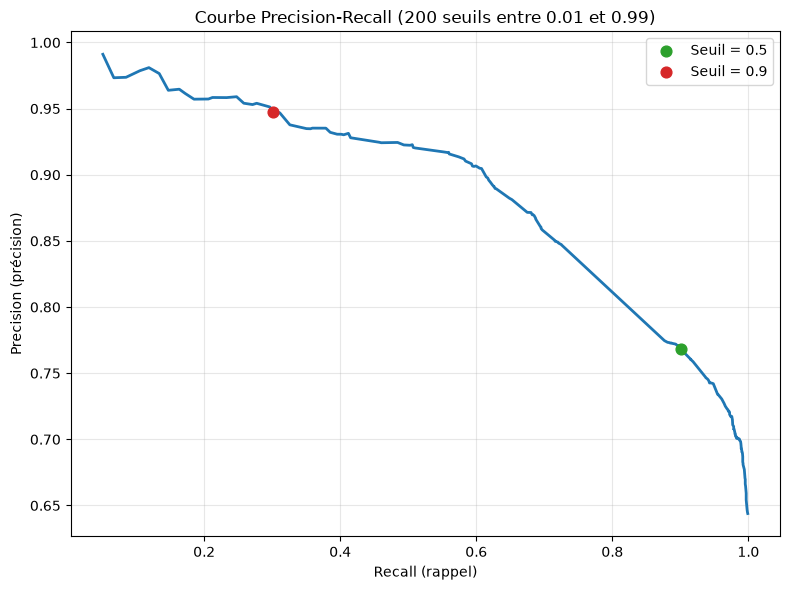

In [27]:
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color="tab:blue", linewidth=2)

for s, couleur in ((0.5, "tab:green"), (0.9, "tab:red")):
    i = int(np.argmin(np.abs(seuils - s)))
    plt.scatter(recalls[i], precisions[i], color=couleur, zorder=5, s=60,
                label=f"Seuil = {s}")

plt.xlabel("Recall (rappel)")
plt.ylabel("Precision (précision)")
plt.title("Courbe Precision-Recall (200 seuils entre 0.01 et 0.99)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("courbe_precision_recall.png", dpi=150)
plt.show()

seuils remarquables (aide à l’interprétation)

In [28]:
#meilleur compromis selon le F1-score
table_pr["f1"] = 2 * table_pr["precision"] * table_pr["recall"] / (table_pr["precision"] + table_pr["recall"])
meilleur = table_pr.loc[table_pr["f1"].idxmax()]
print("Seuil maximisant le F1-score :")
print(meilleur.round(4))

#seuils pour lesquels la précision dépasse 0.90
seuil_p90 = table_pr[table_pr["precision"] >= 0.90].iloc[0]
print("\nPremier seuil avec précision >= 0.90 :")
print(seuil_p90[["seuil", "precision", "recall"]].round(4))

Seuil maximisant le F1-score :
seuil        0.4138
precision    0.7421
recall       0.9484
f1           0.8327
Name: 82, dtype: float64

Premier seuil avec précision >= 0.90 :
seuil        0.7241
precision    0.9031
recall       0.6096
Name: 145, dtype: float64
